# Risk Model

This notebook shows the expected annual flood loss of a dike (thesis Appendix A6).

Flooding is assumed to occur only by overtopping: the annual maximum water level $Y = r\theta + Y_\mathrm{extreme}$ exceeds the dike capacity $h$. Here $\theta$ is the sea level rise, $r$ scales it to account for waves, and $Y_\mathrm{extreme}$ is exponentially distributed with location $a$ and scale $b$. A flood causes the constant damage $D$. The expected annual flood loss is

$$r(h, \theta) = \begin{cases} D\, e^{-\frac{h - r\theta - a}{b}}, & h - r\theta \geq a \\ D, & \text{otherwise.} \end{cases}$$

The parameters are adopted from Jongejan et al.; with $b = 1/\ln 10$ m, every meter of capacity reduces the flood probability by a factor of 10.

## Implementation

`StandardRiskModel` (`source/risk_model.py`) implements this formula; `backward_induction` calls `risk_model.risk_fn(h, theta)` [€/yr] for every candidate decision.

In [ ]:
import numpy as np

from source.risk_model import StandardRiskModel, plot_risk

risk_model = StandardRiskModel(
    r=2.25,  # Scaling factor of sea level rise [-]
    a=0.0,  # Location of the extreme water level [m]s
    b=1 / np.log(10),  # Scale of the extreme water level [m]
    D=10e9,  # Flood damage [€]
)

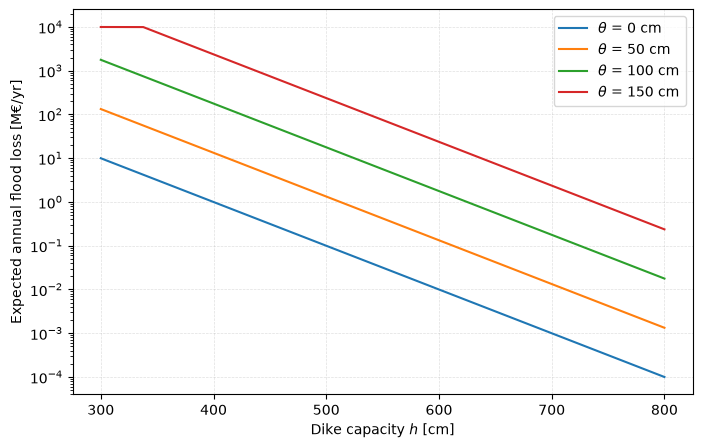

In [2]:
_ = plot_risk(risk_model, heights=np.linspace(3.0, 8.0, 200), states=(0.0, 0.5, 1.0, 1.5))